In [3]:
import numpy as np
import xarray as xr
import pandas as pd
import os
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import pyproj

{'Saint John': 'Dfb', 'Parent': 'Dfc', 'Camrose': 'Dfc', 'Merry Island': 'Cfb'}


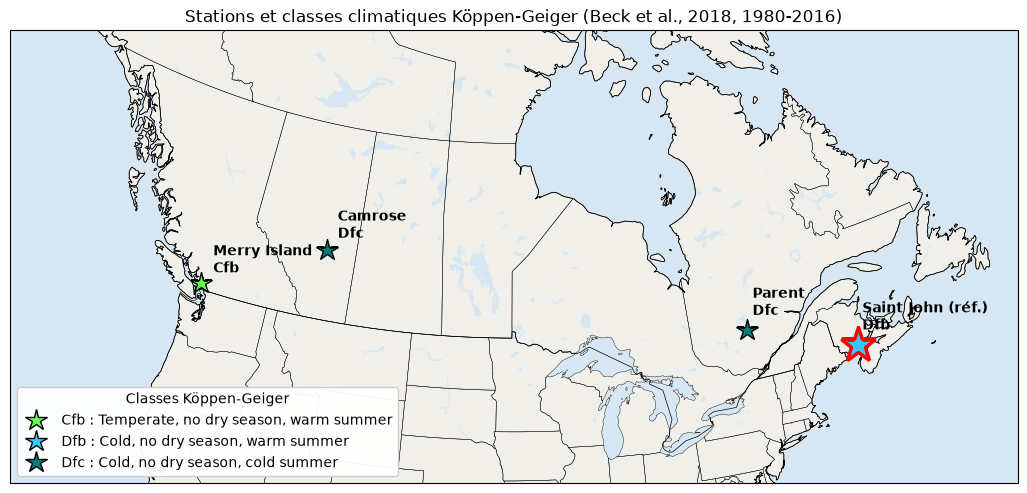

In [4]:
import re
import rasterio
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# --- Légende : code -> nom de classe, et nom -> couleur RGB (0-1)
codes, rgb = {}, {}
for l in open("legend.txt", encoding="utf-8"):
    m = re.match(r"\s*(\d+):\s+(\S+).*\[(\d+) (\d+) (\d+)\]", l)
    if m:
        codes[int(m.group(1))] = m.group(2)
        rgb[m.group(2)] = tuple(int(x) / 255 for x in m.groups()[2:])

# --- Stations (lat, lon) : remplacez par les coordonnées de climatdata.ca
stations = {
    "Saint John":   (45.32, -65.89),
    "Parent":       (47.92, -74.62),
    "Camrose":      (53.02, -112.82),
    "Merry Island": (49.35, -123.28),
}
ref = "Saint John"

# --- Lecture de la classe Köppen dans le raster
with rasterio.open("Beck_KG_V1_present_0p5.tif") as src:
    classes = {n: codes.get(int(next(src.sample([(lon, lat)]))[0]), "?")
               for n, (lat, lon) in stations.items()}
print(classes)

# --- Carte
fig = plt.figure(figsize=(13, 6))
ax = plt.axes(projection=ccrs.LambertConformal(central_longitude=-95, central_latitude=55))
ax.set_extent([-135, -55, 40, 62], ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="#f1efe9")
ax.add_feature(cfeature.OCEAN, facecolor="#d6e6f2")
ax.add_feature(cfeature.LAKES, facecolor="#d6e6f2")
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.add_feature(cfeature.STATES, linewidth=0.3)
ax.coastlines(linewidth=0.6)

for n, (lat, lon) in stations.items():
    c = classes[n]
    is_ref = (n == ref)
    ax.plot(lon, lat, "*", transform=ccrs.PlateCarree(),
            markersize=26 if is_ref else 16,
            color=rgb.get(c, "gray"),
            markeredgecolor="red" if is_ref else "k",
            markeredgewidth=2.5 if is_ref else 1, zorder=5)
    ax.text(lon + 0.8, lat + 0.8, f"{n}{' (réf.)' if is_ref else ''}\n{c}",
            transform=ccrs.PlateCarree(), fontweight="bold", zorder=6)
# Descriptions des classes (lues dans legend.txt)
desc = {}
for l in open("legend.txt", encoding="utf-8"):
    m = re.match(r"\s*\d+:\s+(\S+)\s+(.+?)\s+\[", l)
    if m:
        desc[m.group(1)] = m.group(2)

handles = [Line2D([0], [0], marker="*", linestyle="None", markersize=16,
                  markerfacecolor=rgb[c], markeredgecolor="k",
                  label=f"{c} : {desc[c]}")
           for c in sorted(set(classes.values()))]
ax.legend(handles=handles, title="Classes Köppen-Geiger", loc="lower left", framealpha=0.95)
ax.set_title("Stations et classes climatiques Köppen-Geiger (Beck et al., 2018, 1980-2016)")
plt.savefig("carte_stations_koppen.png", dpi=200, bbox_inches="tight")
plt.show()

Traitement des donnees

In [5]:
# Vérification de la complétude des précipitations quotidiennes

from pathlib import Path

# Le notebook et les fichiers CSV sont dans le dossier courant.
dossier_donnees = Path.cwd()
fichiers_csv = sorted(dossier_donnees.glob("*.csv"))

resultats = []
jours_manquants_toutes_stations = []

for fichier in fichiers_csv:
    donnees = pd.read_csv(fichier)

    colonnes_requises = {"LOCAL_DATE", "TOTAL_PRECIPITATION"}
    colonnes_absentes = colonnes_requises - set(donnees.columns)
    if colonnes_absentes:
        raise ValueError(
            f"{fichier.name}: colonnes absentes: {sorted(colonnes_absentes)}"
        )

    # Une ligne d'en-tête répétée est convertie en NaT puis ignorée.
    donnees["date"] = pd.to_datetime(
        donnees["LOCAL_DATE"], format="mixed", errors="coerce"
    ).dt.normalize()
    donnees["precipitation"] = pd.to_numeric(
        donnees["TOTAL_PRECIPITATION"], errors="coerce"
    )

    dates_invalides = int(donnees["date"].isna().sum())
    donnees_valides = donnees.dropna(subset=["date"]).copy()
    dates_dupliquees = int(donnees_valides["date"].duplicated().sum())
    donnees_journalieres = donnees_valides.drop_duplicates(
        subset="date", keep="first"
    ).set_index("date")

    dates_attendues = pd.date_range(
        donnees_journalieres.index.min(),
        donnees_journalieres.index.max(),
        freq="D",
        name="date",
    )
    dates_absentes = dates_attendues.difference(donnees_journalieres.index)
    precipitations_absentes = donnees_journalieres.index[
        donnees_journalieres["precipitation"].isna()
    ]

    jours_manquants_index = dates_absentes.union(precipitations_absentes)
    jours_absents = pd.DataFrame(index=jours_manquants_index, data={
        "type_manque": "date_absente"
    })
    jours_absents.index.name = "date"
    jours_absents.loc[precipitations_absentes, "type_manque"] = (
        "precipitation_manquante"
    )
    jours_absents = jours_absents.reset_index()
    jours_absents["station"] = fichier.stem
    jours_absents["annee"] = jours_absents["date"].dt.year
    jours_absents["mois"] = jours_absents["date"].dt.month
    jours_absents["jour"] = jours_absents["date"].dt.day
    jours_manquants_toutes_stations.append(jours_absents)

    resultats.append({
        "station": fichier.stem,
        "date_debut": donnees_journalieres.index.min().date(),
        "date_fin": donnees_journalieres.index.max().date(),
        "jours_attendus": len(dates_attendues),
        "jours_observes": len(donnees_journalieres),
        "dates_absentes": len(dates_absentes),
        "precipitations_manquantes": len(precipitations_absentes),
        "dates_invalides": dates_invalides,
        "dates_dupliquees": dates_dupliquees,
    })

resume_completude = pd.DataFrame(resultats).sort_values("station")
jours_manquants = pd.concat(
    jours_manquants_toutes_stations, ignore_index=True
)

manquants_par_mois = (
    jours_manquants.groupby(
        ["station", "annee", "mois", "type_manque"]
    ).size().reset_index(name="nombre_jours_manquants")
)
manquants_par_annee = (
    jours_manquants.groupby(
        ["station", "annee", "type_manque"]
    ).size().reset_index(name="nombre_jours_manquants")
)

print("Résumé de complétude")
display(resume_completude)

print("Jours manquants par mois")
display(manquants_par_mois)

print("Jours manquants par année")
display(manquants_par_annee)

print("Liste détaillée des jours manquants")
display(jours_manquants)


Résumé de complétude


,station,date_debut,date_fin,jours_attendus,jours_observes,dates_absentes,precipitations_manquantes,dates_invalides,dates_dupliquees
0,Camerose,1971-01-01,2000-12-31,10958,10958,0,503,1,0
1,Merry,1971-01-01,2000-12-31,10958,10958,0,62,0,0
3,Saint_john,1971-01-01,2000-12-31,10958,10958,0,1,0,0
2,parent,1971-01-01,2000-12-31,10958,10958,0,6944,0,0


Jours manquants par mois


,station,annee,mois,type_manque,nombre_jours_manquants
0,Camerose,1979,7,precipitation_manquante,31
1,Camerose,1984,12,precipitation_manquante,7
2,Camerose,1985,11,precipitation_manquante,12
3,Camerose,1986,11,precipitation_manquante,7
4,Camerose,1987,3,precipitation_manquante,10
...,...,...,...,...,...
290,parent,2000,5,precipitation_manquante,8
291,parent,2000,8,precipitation_manquante,1
292,parent,2000,9,precipitation_manquante,1
293,parent,2000,11,precipitation_manquante,1


Jours manquants par année


,station,annee,type_manque,nombre_jours_manquants
0,Camerose,1979,precipitation_manquante,31
1,Camerose,1984,precipitation_manquante,7
2,Camerose,1985,precipitation_manquante,12
3,Camerose,1986,precipitation_manquante,7
4,Camerose,1987,precipitation_manquante,10
5,Camerose,1989,precipitation_manquante,9
6,Camerose,1990,precipitation_manquante,31
7,Camerose,1991,precipitation_manquante,122
8,Camerose,1992,precipitation_manquante,11
9,Camerose,1993,precipitation_manquante,140


Liste détaillée des jours manquants


,date,type_manque,station,annee,mois,jour
0,1979-07-01,precipitation_manquante,Camerose,1979,7,1
1,1979-07-02,precipitation_manquante,Camerose,1979,7,2
2,1979-07-03,precipitation_manquante,Camerose,1979,7,3
3,1979-07-04,precipitation_manquante,Camerose,1979,7,4
4,1979-07-05,precipitation_manquante,Camerose,1979,7,5
...,...,...,...,...,...,...
7505,2000-12-28,precipitation_manquante,parent,2000,12,28
7506,2000-12-29,precipitation_manquante,parent,2000,12,29
7507,2000-12-30,precipitation_manquante,parent,2000,12,30
7508,2000-12-31,precipitation_manquante,parent,2000,12,31


## Étape 1 - Fusion des nouvelles données par station

In [6]:
from pathlib import Path

dossier_nouvelles_donnees = Path.cwd() / "New_data"
dossier_fusion = Path.cwd() / "Merged_data"
dossier_fusion.mkdir(exist_ok=True)

colonnes_utiles = [
    "x", "y", "STATION_NAME", "CLIMATE_IDENTIFIER", "ID",
    "LOCAL_DATE", "PROVINCE_CODE", "LOCAL_YEAR", "LOCAL_MONTH",
    "LOCAL_DAY", "TOTAL_PRECIPITATION",
]

fichiers_csv = sorted(dossier_nouvelles_donnees.glob("*.csv"))
donnees_par_station = {}

for fichier in fichiers_csv:
    donnees = pd.read_csv(fichier, low_memory=False)
    colonnes_absentes = set(colonnes_utiles) - set(donnees.columns)
    if colonnes_absentes:
        raise ValueError(
            f"{fichier.name}: colonnes absentes: {sorted(colonnes_absentes)}"
        )

    # On elimine ici toutes les colonnes qui ne sont pas utiles a l'analyse.
    donnees = donnees[colonnes_utiles]
    identifiants = donnees["CLIMATE_IDENTIFIER"].dropna().unique()
    if len(identifiants) != 1:
        raise ValueError(
            f"{fichier.name}: identifiant de station ambigu: {identifiants}"
        )
    donnees_par_station.setdefault(str(identifiants[0]), []).append(donnees)

resume_fusion = []
for identifiant, morceaux in donnees_par_station.items():
    fusion = pd.concat(morceaux, ignore_index=True)
    fusion["LOCAL_DATE"] = pd.to_datetime(
        fusion["LOCAL_DATE"], format="mixed", errors="coerce"
    )
    dates_invalides = int(fusion["LOCAL_DATE"].isna().sum())
    fusion = fusion.dropna(subset=["LOCAL_DATE"])
    doublons = int(fusion.duplicated(subset=["LOCAL_DATE"]).sum())
    fusion = (
        fusion.sort_values("LOCAL_DATE")
        .drop_duplicates(subset=["LOCAL_DATE"], keep="first")
    )
    fusion["LOCAL_DATE"] = fusion["LOCAL_DATE"].dt.strftime(
        "%Y-%m-%d %H:%M:%S"
    )
    nom_station = str(fusion["STATION_NAME"].iloc[0]).strip()
    nom_station = nom_station.replace(" ", "_").replace("/", "_")
    chemin_sortie = dossier_fusion / f"{nom_station}_{identifiant}.csv"
    fusion.to_csv(chemin_sortie, index=False)
    resume_fusion.append({
        "station": nom_station,
        "identifiant": identifiant,
        "fichiers_fusionnes": len(morceaux),
        "lignes_finales": len(fusion),
        "date_debut": fusion["LOCAL_DATE"].min(),
        "date_fin": fusion["LOCAL_DATE"].max(),
        "doublons_supprimes": doublons,
        "dates_invalides": dates_invalides,
        "fichier_sortie": str(chemin_sortie),
    })
resume_fusion = pd.DataFrame(resume_fusion).sort_values("station")
display(resume_fusion)


,station,identifiant,fichiers_fusionnes,lignes_finales,date_debut,date_fin,doublons_supprimes,dates_invalides,fichier_sortie
0,CAMROSE_2,3011241,3,29052,1947-04-01 00:00:00,2026-10-14 00:00:00,0,0,c:\Users\MAGI\Climate_Projet1\Merged_data\CAMR...
1,MERRY_ISLAND_LIGHTSTATION,1045100,3,25185,1957-11-01 00:00:00,2026-10-14 00:00:00,0,0,c:\Users\MAGI\Climate_Projet1\Merged_data\MERR...
2,PARENT_S,7075799,2,16207,1982-06-01 00:00:00,2026-10-14 00:00:00,0,0,c:\Users\MAGI\Climate_Projet1\Merged_data\PARE...
3,SAINT_JOHN_A,8104900,3,29203,1946-11-01 00:00:00,2026-10-14 00:00:00,0,0,c:\Users\MAGI\Climate_Projet1\Merged_data\SAIN...


## Étape 2 - Sélection d'une période de 30 ans selon la complétude

Un mois est valide si au moins 85 % de ses jours contiennent une valeur de précipitation. Une année est valide si au moins 85 % de ses mois sont valides. Les fenêtres continues de 30 ans sont ensuite comparées.

In [7]:
SEUIL_MOIS = 0.85
SEUIL_ANNEE = 0.85
DUREE_PERIODE = 30

# Une seule periode de 30 ans sera comparee pour toutes les stations.
dossier_fusion = Path.cwd() / "Merged_data"
fichiers_fusionnes = sorted(dossier_fusion.glob("*.csv"))
if not fichiers_fusionnes:
    raise FileNotFoundError(f"Aucun fichier CSV trouve dans {dossier_fusion}")

resultats_mois = []
resultats_annees = []
donnees_stations = {}

for fichier in fichiers_fusionnes:
    donnees = pd.read_csv(fichier, low_memory=False)
    colonnes_requises = {"LOCAL_DATE", "TOTAL_PRECIPITATION", "STATION_NAME"}
    colonnes_absentes = colonnes_requises - set(donnees.columns)
    if colonnes_absentes:
        raise ValueError(
            f"{fichier.name}: colonnes absentes: {sorted(colonnes_absentes)}"
        )

    donnees["date"] = pd.to_datetime(
        donnees["LOCAL_DATE"], format="mixed", errors="coerce"
    ).dt.normalize()
    donnees["precipitation"] = pd.to_numeric(
        donnees["TOTAL_PRECIPITATION"], errors="coerce"
    )
    donnees = (
        donnees.dropna(subset=["date"])
        .drop_duplicates(subset=["date"], keep="first")
        .set_index("date")
    )
    station = str(donnees["STATION_NAME"].iloc[0])
    donnees_stations[station] = donnees["precipitation"]

# Intersection des annees disponibles dans les quatre stations.
annee_debut_commune = max(series.index.min().year for series in donnees_stations.values())
annee_fin_commune = min(series.index.max().year for series in donnees_stations.values())
if annee_fin_commune - annee_debut_commune + 1 < DUREE_PERIODE:
    raise ValueError("Les quatre stations ne possedent pas 30 annees communes.")

resultats_fenetres = []
for debut in range(
    annee_debut_commune,
    annee_fin_commune - DUREE_PERIODE + 2,
):
    fin = debut + DUREE_PERIODE - 1
    annees_fenetre = range(debut, fin + 1)
    resume_stations = []

    for station, precipitation in donnees_stations.items():
        dates_fenetre = pd.date_range(
            f"{debut}-01-01", f"{fin}-12-31", freq="D"
        )
        quotidien = precipitation.reindex(dates_fenetre).to_frame("precipitation")
        quotidien["jour_valide"] = quotidien["precipitation"].notna()
        quotidien["annee"] = quotidien.index.year
        quotidien["mois"] = quotidien.index.month

        mensuel = (
            quotidien.groupby(["annee", "mois"])
            .agg(
                jours_attendus=("jour_valide", "size"),
                jours_valides=("jour_valide", "sum"),
            )
            .reset_index()
        )
        mensuel["station"] = station
        mensuel["proportion_valide"] = (
            mensuel["jours_valides"] / mensuel["jours_attendus"]
        )
        mensuel["mois_valide"] = (
            mensuel["proportion_valide"] >= SEUIL_MOIS
        )
        mensuel["debut_fenetre"] = debut
        mensuel["fin_fenetre"] = fin
        resultats_mois.append(mensuel)

        annuel = (
            mensuel.groupby(["station", "annee"])
            .agg(
                mois_attendus=("mois", "size"),
                mois_valides=("mois_valide", "sum"),
                jours_attendus=("jours_attendus", "sum"),
                jours_valides=("jours_valides", "sum"),
            )
            .reset_index()
        )
        annuel["proportion_mois_valides"] = (
            annuel["mois_valides"] / annuel["mois_attendus"]
        )
        annuel["annee_valide"] = (
            annuel["proportion_mois_valides"] >= SEUIL_ANNEE
        )
        annuel["debut_fenetre"] = debut
        annuel["fin_fenetre"] = fin
        resultats_annees.append(annuel)

        resume_stations.append({
            "station": station,
            "annees_valides": int(annuel["annee_valide"].sum()),
            "proportion_annees_valides": annuel["annee_valide"].mean(),
            "mois_valides": int(mensuel["mois_valide"].sum()),
            "mois_attendus": len(mensuel),
            "proportion_mois_valides": mensuel["mois_valide"].mean(),
        })

    # Une fenetre est acceptable seulement si chaque station atteint 85 %
    # d'annees valides sur les memes 30 annees.
    resultats_fenetres.append({
        "debut": debut,
        "fin": fin,
        "fenetre_valide_pour_toutes": all(
            item["proportion_annees_valides"] >= SEUIL_ANNEE
            for item in resume_stations
        ),
        "proportion_annees_min_station": min(
            item["proportion_annees_valides"] for item in resume_stations
        ),
        "proportion_mois_min_station": min(
            item["proportion_mois_valides"] for item in resume_stations
        ),
        "details_stations": resume_stations,
    })

completude_mensuelle = pd.concat(resultats_mois, ignore_index=True)
completude_annuelle = pd.concat(resultats_annees, ignore_index=True)
comparaison_30_ans = pd.DataFrame(resultats_fenetres)

# Classement des fenetres communes : d'abord celles acceptables pour toutes,
# puis la moins bonne station et enfin la proportion mensuelle minimale.
comparaison_30_ans = comparaison_30_ans.sort_values(
    ["fenetre_valide_pour_toutes", "proportion_annees_min_station",
     "proportion_mois_min_station", "debut"],
    ascending=[False, False, False, True],
).reset_index(drop=True)
meilleure_periode_commune = comparaison_30_ans.head(1)

print("Periode commune disponible :", annee_debut_commune, "a", annee_fin_commune)
print("Meilleure fenetre commune de 30 ans")
display(meilleure_periode_commune[[
    "debut", "fin", "fenetre_valide_pour_toutes",
    "proportion_annees_min_station", "proportion_mois_min_station",
]])

# Detail de chaque station pour la meilleure fenetre commune.
details_meilleure_periode = pd.DataFrame(
    meilleure_periode_commune.iloc[0]["details_stations"]
)
display(details_meilleure_periode)

# Statistiques completes pour toutes les fenetres et tous les mois/annees.
display(comparaison_30_ans.drop(columns=["details_stations"]))
display(completude_annuelle)
display(completude_mensuelle)

# Sauvegarde des statistiques dans des fichiers CSV.
dossier_resultats_etape2 = Path.cwd() / "completude_precipitations_etape2"
dossier_resultats_etape2.mkdir(parents=True, exist_ok=True)

completude_mensuelle.to_csv(
    dossier_resultats_etape2 / "completude_mensuelle.csv",
    index=False,
)
completude_annuelle.to_csv(
    dossier_resultats_etape2 / "completude_annuelle.csv",
    index=False,
)
comparaison_30_ans.drop(columns=["details_stations"]).to_csv(
    dossier_resultats_etape2 / "comparaison_fenetres_30_ans.csv",
    index=False,
)
meilleure_periode_commune.to_csv(
    dossier_resultats_etape2 / "meilleure_periode_commune.csv",
    index=False,
)
details_meilleure_periode.to_csv(
    dossier_resultats_etape2 / "details_meilleure_periode.csv",
    index=False,
)

print(
    "Statistiques sauvegardees dans :",
    dossier_resultats_etape2.resolve(),
)


Periode commune disponible : 1982 a 2026
Meilleure fenetre commune de 30 ans


,debut,fin,fenetre_valide_pour_toutes,proportion_annees_min_station,proportion_mois_min_station
0,1982,2011,False,0.433333,0.511111


,station,annees_valides,proportion_annees_valides,mois_valides,mois_attendus,proportion_mois_valides
0,CAMROSE 2,26,0.866667,333,360,0.925000
1,MERRY ISLAND LIGHTSTATION,27,0.900000,345,360,0.958333
2,PARENT S,13,0.433333,184,360,0.511111
3,SAINT JOHN A,30,1.000000,360,360,1.000000


,debut,fin,fenetre_valide_pour_toutes,proportion_annees_min_station,proportion_mois_min_station
0,1982,2011,False,0.433333,0.511111
1,1983,2012,False,0.433333,0.494444
2,1984,2013,False,0.433333,0.480556
3,1985,2014,False,0.400000,0.447222
4,1986,2015,False,0.366667,0.413889
5,1987,2016,False,0.333333,0.380556
6,1988,2017,False,0.300000,0.347222
7,1989,2018,False,0.266667,0.313889
8,1990,2019,False,0.233333,0.280556
9,1991,2020,False,0.200000,0.247222


,station,annee,mois_attendus,mois_valides,jours_attendus,jours_valides,proportion_mois_valides,annee_valide,debut_fenetre,fin_fenetre
0,CAMROSE 2,1982,12,12,365,365,1.000000,True,1982,2011
1,CAMROSE 2,1983,12,12,365,365,1.000000,True,1982,2011
2,CAMROSE 2,1984,12,11,366,359,0.916667,True,1982,2011
3,CAMROSE 2,1985,12,11,365,353,0.916667,True,1982,2011
4,CAMROSE 2,1986,12,11,365,358,0.916667,True,1982,2011
...,...,...,...,...,...,...,...,...,...,...
1915,SAINT JOHN A,2022,12,0,365,0,0.000000,False,1997,2026
1916,SAINT JOHN A,2023,12,0,365,0,0.000000,False,1997,2026
1917,SAINT JOHN A,2024,12,0,366,0,0.000000,False,1997,2026
1918,SAINT JOHN A,2025,12,0,365,0,0.000000,False,1997,2026


,annee,mois,jours_attendus,jours_valides,station,proportion_valide,mois_valide,debut_fenetre,fin_fenetre
0,1982,1,31,31,CAMROSE 2,1.0,True,1982,2011
1,1982,2,28,28,CAMROSE 2,1.0,True,1982,2011
2,1982,3,31,31,CAMROSE 2,1.0,True,1982,2011
3,1982,4,30,30,CAMROSE 2,1.0,True,1982,2011
4,1982,5,31,31,CAMROSE 2,1.0,True,1982,2011
...,...,...,...,...,...,...,...,...,...
23035,2026,8,31,0,SAINT JOHN A,0.0,False,1997,2026
23036,2026,9,30,0,SAINT JOHN A,0.0,False,1997,2026
23037,2026,10,31,0,SAINT JOHN A,0.0,False,1997,2026
23038,2026,11,30,0,SAINT JOHN A,0.0,False,1997,2026


Statistiques sauvegardees dans : C:\Users\MAGI\Climate_Projet1\completude_precipitations_etape2


## Filtrage de la période de référence : 1971-2000

In [8]:
from pathlib import Path

ANNEE_DEBUT = 1971
ANNEE_FIN = 2000

dossier_fusion = Path.cwd() / "Merged_data"
dossier_reference = Path.cwd() / "Donnees_1971_2000"
dossier_reference.mkdir(parents=True, exist_ok=True)

fichiers_fusionnes = sorted(dossier_fusion.glob("*.csv"))
if not fichiers_fusionnes:
    raise FileNotFoundError(
        f"Aucun fichier CSV trouvé dans {dossier_fusion}"
    )

resume_periode = []

for fichier in fichiers_fusionnes:
    donnees = pd.read_csv(fichier, low_memory=False)
    colonnes_requises = {"LOCAL_DATE", "STATION_NAME"}
    colonnes_absentes = colonnes_requises - set(donnees.columns)
    if colonnes_absentes:
        raise ValueError(
            f"{fichier.name}: colonnes absentes: {sorted(colonnes_absentes)}"
        )

    donnees["LOCAL_DATE"] = pd.to_datetime(
        donnees["LOCAL_DATE"], format="mixed", errors="coerce"
    )
    donnees = donnees.dropna(subset=["LOCAL_DATE"])
    masque_periode = donnees["LOCAL_DATE"].dt.year.between(
        ANNEE_DEBUT, ANNEE_FIN
    )
    donnees_periode = donnees.loc[masque_periode].copy()
    donnees_periode = donnees_periode.sort_values("LOCAL_DATE")
    donnees_periode["LOCAL_DATE"] = donnees_periode["LOCAL_DATE"].dt.strftime(
        "%Y-%m-%d %H:%M:%S"
    )

    chemin_sortie = dossier_reference / fichier.name
    donnees_periode.to_csv(chemin_sortie, index=False)
    resume_periode.append({
        "station": str(donnees_periode["STATION_NAME"].iloc[0]),
        "fichier_sortie": str(chemin_sortie),
        "date_debut": donnees_periode["LOCAL_DATE"].min(),
        "date_fin": donnees_periode["LOCAL_DATE"].max(),
        "nombre_lignes": len(donnees_periode),
    })

resume_periode_1971_2000 = pd.DataFrame(resume_periode)
display(resume_periode_1971_2000)
print("Données filtrées enregistrées dans :", dossier_reference.resolve())


,station,fichier_sortie,date_debut,date_fin,nombre_lignes
0,CAMROSE 2,c:\Users\MAGI\Climate_Projet1\Donnees_1971_200...,1971-01-01 00:00:00,2000-12-31 00:00:00,10958
1,MERRY ISLAND LIGHTSTATION,c:\Users\MAGI\Climate_Projet1\Donnees_1971_200...,1971-01-01 00:00:00,2000-12-31 00:00:00,10958
2,PARENT S,c:\Users\MAGI\Climate_Projet1\Donnees_1971_200...,1982-06-01 00:00:00,2000-12-31 00:00:00,6789
3,SAINT JOHN A,c:\Users\MAGI\Climate_Projet1\Donnees_1971_200...,1971-01-01 00:00:00,2000-12-31 00:00:00,10958


Données filtrées enregistrées dans : C:\Users\MAGI\Climate_Projet1\Donnees_1971_2000


## Nombre de valeurs manquantes par station`n

In [9]:
dossier_donnees = Path.cwd() / "Donnees_1971_2000"
dossier_resultats_manquants = Path.cwd() / "completude_precipitations_etape2"
dossier_resultats_manquants.mkdir(parents=True, exist_ok=True)

fichiers_stations = sorted(dossier_donnees.glob("*.csv"))
if not fichiers_stations:
    raise FileNotFoundError(f"Aucun fichier CSV trouve dans {dossier_donnees}")

resultats_valeurs_manquantes = []

for fichier in fichiers_stations:
    donnees = pd.read_csv(fichier, low_memory=False)
    colonnes_requises = {"STATION_NAME", "TOTAL_PRECIPITATION"}
    colonnes_absentes = colonnes_requises - set(donnees.columns)
    if colonnes_absentes:
        raise ValueError(f"{fichier.name}: colonnes absentes: {sorted(colonnes_absentes)}")

    precipitation = pd.to_numeric(donnees["TOTAL_PRECIPITATION"], errors="coerce")
    nombre_total = len(donnees)
    nombre_manquant = int(precipitation.isna().sum())
    nombre_valide = nombre_total - nombre_manquant
    resultats_valeurs_manquantes.append({
        "station": str(donnees["STATION_NAME"].iloc[0]),
        "fichier": fichier.name,
        "nombre_total_valeurs": nombre_total,
        "nombre_valeurs_valides": nombre_valide,
        "nombre_valeurs_manquantes": nombre_manquant,
        "proportion_manquante": nombre_manquant / nombre_total,
        "proportion_valide": nombre_valide / nombre_total,
    })

valeurs_manquantes_par_station = pd.DataFrame(resultats_valeurs_manquantes).sort_values("station")
chemin_valeurs_manquantes = dossier_resultats_manquants / "valeurs_manquantes_par_station.csv"
valeurs_manquantes_par_station.to_csv(chemin_valeurs_manquantes, index=False)
display(valeurs_manquantes_par_station)
print("Resultats enregistres dans:", chemin_valeurs_manquantes.resolve())


,station,fichier,nombre_total_valeurs,nombre_valeurs_valides,nombre_valeurs_manquantes,proportion_manquante,proportion_valide
0,CAMROSE 2,CAMROSE_2_3011241.csv,10958,10455,503,0.045903,0.954097
1,MERRY ISLAND LIGHTSTATION,MERRY_ISLAND_LIGHTSTATION_1045100.csv,10958,10896,62,0.005658,0.994342
2,PARENT S,PARENT_S_7075799.csv,6789,5378,1411,0.207836,0.792164
3,SAINT JOHN A,SAINT_JOHN_A_8104900.csv,10958,10957,1,0.000091,0.999909


Resultats enregistres dans: C:\Users\MAGI\Climate_Projet1\completude_precipitations_etape2\valeurs_manquantes_par_station.csv


## Précipitation annuelle moyenne et moyenne mensuelle à long terme (1971-2000)`n

In [10]:
dossier_donnees = Path.cwd() / "Donnees_1971_2000"
dossier_resultats = Path.cwd() / "completude_precipitations_etape2"
dossier_resultats.mkdir(parents=True, exist_ok=True)

fichiers_stations = sorted(dossier_donnees.glob("*.csv"))
if not fichiers_stations:
    raise FileNotFoundError(f"Aucun fichier CSV trouve dans {dossier_donnees}")

resultats_annuels = []
resultats_mensuels = []

for fichier in fichiers_stations:
    donnees = pd.read_csv(fichier, low_memory=False)
    colonnes_requises = {"STATION_NAME", "LOCAL_DATE", "TOTAL_PRECIPITATION"}
    colonnes_absentes = colonnes_requises - set(donnees.columns)
    if colonnes_absentes:
        raise ValueError(f"{fichier.name}: colonnes absentes: {sorted(colonnes_absentes)}")

    donnees["date"] = pd.to_datetime(
        donnees["LOCAL_DATE"], format="mixed", errors="coerce"
    )
    donnees["precipitation"] = pd.to_numeric(
        donnees["TOTAL_PRECIPITATION"], errors="coerce"
    )
    donnees = donnees.dropna(subset=["date"])
    donnees = donnees.loc[donnees["date"].dt.year.between(1971, 2000)].copy()
    donnees["annee"] = donnees["date"].dt.year
    donnees["mois"] = donnees["date"].dt.month
    station = str(donnees["STATION_NAME"].iloc[0])

    # Partie 1 : cumul annuel divise par le nombre de jours valides de l'annee.
    annuels = (
        donnees.groupby("annee", as_index=False)
        .agg(
            cumul_precipitation=("precipitation", "sum"),
            nombre_jours_valides=("precipitation", "count"),
        )
    )
    annuels["precipitation_moyenne_par_jour"] = (
        annuels["cumul_precipitation"] / annuels["nombre_jours_valides"]
    )
    annuels["station"] = station
    annuels["fichier"] = fichier.name
    resultats_annuels.append(annuels)

    # Partie 2 : pour chaque mois, cumul sur les 30 ans divise par
    # le nombre total de jours valides de ce mois pendant ces 30 ans.
    mensuels = (
        donnees.groupby("mois", as_index=False)
        .agg(
            cumul_precipitation_30_ans=("precipitation", "sum"),
            nombre_jours_valides_30_ans=("precipitation", "count"),
        )
    )
    mensuels["precipitation_moyenne_long_terme"] = (
        mensuels["cumul_precipitation_30_ans"]
        / mensuels["nombre_jours_valides_30_ans"]
    )
    mensuels["station"] = station
    mensuels["fichier"] = fichier.name
    resultats_mensuels.append(mensuels)

precipitation_annuelle = pd.concat(resultats_annuels, ignore_index=True)
precipitation_mensuelle_long_terme = pd.concat(
    resultats_mensuels, ignore_index=True
).sort_values(["station", "mois"])

precipitation_annuelle.to_csv(
    dossier_resultats / "precipitation_moyenne_par_annee_1971_2000.csv",
    index=False,
)
precipitation_mensuelle_long_terme.to_csv(
    dossier_resultats / "precipitation_moyenne_mensuelle_long_terme_1971_2000.csv",
    index=False,
)

display(precipitation_annuelle)
display(precipitation_mensuelle_long_terme)
print("Resultats enregistres dans:", dossier_resultats.resolve())


,annee,cumul_precipitation,nombre_jours_valides,precipitation_moyenne_par_jour,station,fichier
0,1971,358.4,365,0.981918,CAMROSE 2,CAMROSE_2_3011241.csv
1,1972,501.6,366,1.370492,CAMROSE 2,CAMROSE_2_3011241.csv
2,1973,686.8,365,1.881644,CAMROSE 2,CAMROSE_2_3011241.csv
3,1974,515.9,365,1.413425,CAMROSE 2,CAMROSE_2_3011241.csv
4,1975,420.2,365,1.151233,CAMROSE 2,CAMROSE_2_3011241.csv
...,...,...,...,...,...,...
104,1996,1263.6,366,3.452459,SAINT JOHN A,SAINT_JOHN_A_8104900.csv
105,1997,979.4,365,2.683288,SAINT JOHN A,SAINT_JOHN_A_8104900.csv
106,1998,1137.3,365,3.115890,SAINT JOHN A,SAINT_JOHN_A_8104900.csv
107,1999,1236.7,365,3.388219,SAINT JOHN A,SAINT_JOHN_A_8104900.csv


,mois,cumul_precipitation_30_ans,nombre_jours_valides_30_ans,precipitation_moyenne_long_terme,station,fichier
0,1,733.0,930,0.788172,CAMROSE 2,CAMROSE_2_3011241.csv
1,2,478.5,842,0.568290,CAMROSE 2,CAMROSE_2_3011241.csv
2,3,619.5,903,0.686047,CAMROSE 2,CAMROSE_2_3011241.csv
3,4,685.1,900,0.761222,CAMROSE 2,CAMROSE_2_3011241.csv
4,5,1376.0,888,1.549550,CAMROSE 2,CAMROSE_2_3011241.csv
5,6,2364.9,870,2.718276,CAMROSE 2,CAMROSE_2_3011241.csv
6,7,2559.9,878,2.915604,CAMROSE 2,CAMROSE_2_3011241.csv
7,8,1809.6,872,2.075229,CAMROSE 2,CAMROSE_2_3011241.csv
8,9,1276.7,870,1.467471,CAMROSE 2,CAMROSE_2_3011241.csv
9,10,461.5,830,0.556024,CAMROSE 2,CAMROSE_2_3011241.csv


Resultats enregistres dans: C:\Users\MAGI\Climate_Projet1\completude_precipitations_etape2


## Comparaison des climatologies mensuelles`n

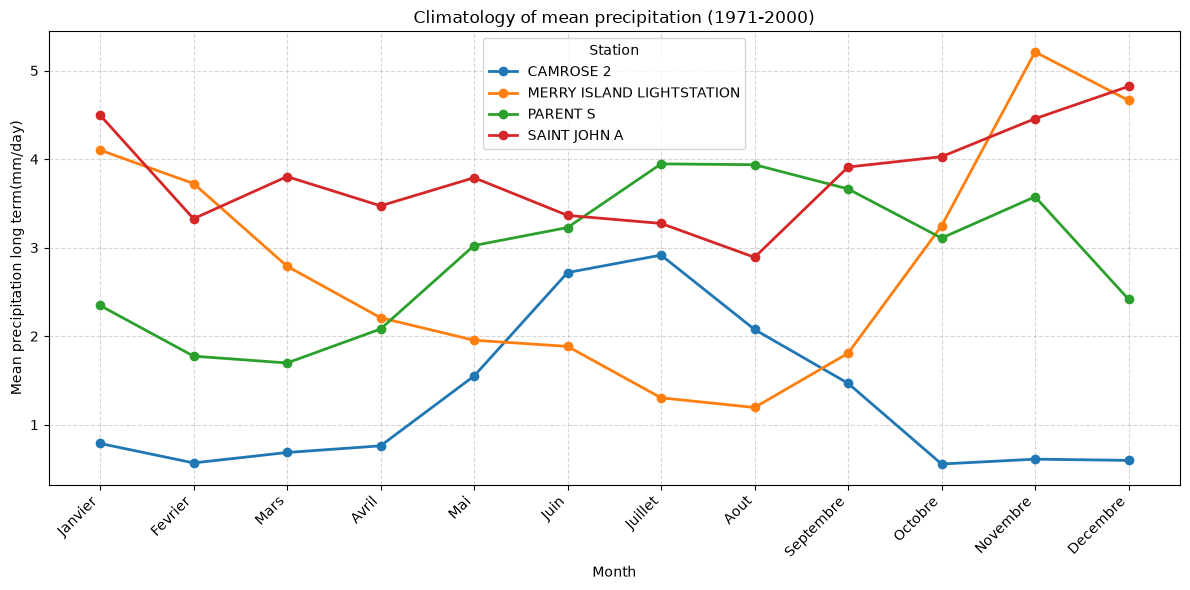

In [13]:
# Vérification de la présence du tableau produit à l'étape précédente.
if "precipitation_mensuelle_long_terme" not in locals():
    raise NameError(
        "Executez d'abord la cellule de calcul des moyennes mensuelles "
        "a long terme."
    )

mois_noms = [
    "Janvier", "Fevrier", "Mars", "Avril", "Mai", "Juin",
    "Juillet", "Aout", "Septembre", "Octobre", "Novembre", "Decembre",
]

figure, axe = plt.subplots(figsize=(12, 6))

for station, donnees_station in precipitation_mensuelle_long_terme.groupby("station"):
    donnees_station = donnees_station.sort_values("mois")
    axe.plot(
        donnees_station["mois"],
        donnees_station["precipitation_moyenne_long_terme"],
        marker="o",
        linewidth=2,
        label=station,
    )

axe.set_xticks(range(1, 13))
axe.set_xticklabels(mois_noms, rotation=45, ha="right")
axe.set_xlabel("Month")
axe.set_ylabel("Mean precipitation long term(mm/day)")
axe.set_title(
    "Climatology of mean precipitation "
    "(1971-2000)"
)
axe.grid(True, linestyle="--", alpha=0.5)
axe.legend(title="Station")
figure.tight_layout()
plt.show()

figure.savefig(
    dossier_resultats / "climatologies_mensuelles_1971_2000.png",
    dpi=300,
    bbox_inches="tight",
)
